# Food Delivery Delay Analysis (Synthetic Data)
**Question:** Which areas, hours and weather conditions make deliveries late and hurt customer ratings?

Data is synthetic (computer-generated). Findings describe this dataset and show the method.
Late = delivered more than 5 minutes after the promised time.

## 1. Setup and load data

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

try:
    ROOT = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..")
except NameError:                      # running inside a notebook
    ROOT = ".."
VIZ = os.path.join(ROOT, "visualizations"); os.makedirs(VIZ, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
def save(name):
    plt.tight_layout(); plt.savefig(os.path.join(VIZ, name), dpi=130); 

df = pd.read_csv(os.path.join(ROOT, "data", "cleaned", "clean_deliveries.csv"), parse_dates=["order_datetime"])
raw = pd.read_csv(os.path.join(ROOT, "data", "raw", "raw_deliveries.csv"))
print("Raw rows:", len(raw), "| Clean rows:", len(df))
df.head()

Raw rows: 6035 | Clean rows: 5985

   order_id      order_datetime  ...    month distance_band
0  FD104690 2025-01-01 07:49:00  ...  January        4-6 km
1  FD104884 2025-01-01 08:35:00  ...  January        2-4 km
2  FD105082 2025-01-01 09:39:00  ...  January        4-6 km
3  FD101487 2025-01-01 10:38:00  ...  January        4-6 km
4  FD101738 2025-01-01 11:05:00  ...  January        0-2 km

[5 rows x 23 columns]

## 2. Data inspection

In [2]:
print(df.dtypes.to_string())
print("\nMissing values per column (clean data):")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print("\nDuplicate order_id:", df.order_id.duplicated().sum())
df[["distance_km", "prep_time_min", "promised_time_min", "actual_time_min", "delay_min", "customer_rating"]].describe().round(2)

order_id                                str
order_datetime               datetime64[us]
zone                                    str
cuisine                                 str
distance_km                         float64
items_count                           int64
order_value                         float64
weather                                 str
traffic_level                           str
courier_experience_months             int64
prep_time_min                       float64
promised_time_min                   float64
actual_time_min                     float64
customer_rating                     float64
payment_method                          str
delay_min                           float64
is_late                               int64
hour                                  int64
day_of_week                             str
is_weekend                             bool
is_peak_hour                           bool
month                                   str
distance_band                   

       distance_km  prep_time_min  ...  delay_min  customer_rating
count      5985.00         5985.0  ...    5985.00          5505.00
mean          4.05           16.5  ...      -2.22             4.55
std           2.34            5.2  ...       7.10             0.57
min           0.40            4.0  ...     -26.00             2.00
25%           2.30           12.7  ...      -7.00             4.00
50%           3.60           16.2  ...      -2.00             5.00
75%           5.30           20.2  ...       3.00             5.00
max          14.00           34.2  ...      25.00             5.00

[8 rows x 6 columns]

## 3. Headline KPIs

In [3]:
kpi = {
    "orders": len(df),
    "avg_actual_min": df.actual_time_min.mean(),
    "avg_delay_min": df.delay_min.mean(),
    "late_pct": df.is_late.mean() * 100,
    "avg_rating": df.customer_rating.mean(),
    "rating_response_pct": df.customer_rating.notna().mean() * 100,
}
for k, v in kpi.items(): print(f"{k:22s}: {v:,.2f}")

orders                : 5,985.00
avg_actual_min        : 54.31
avg_delay_min         : -2.22
late_pct              : 13.68
avg_rating            : 4.55
rating_response_pct   : 91.98

## 4. Distribution of delay

Skewness of delay: 0.05

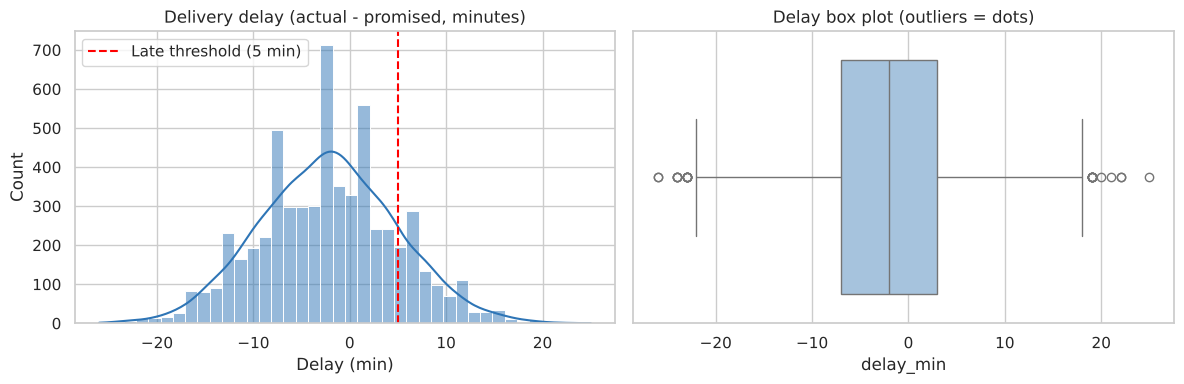

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.delay_min, bins=40, kde=True, ax=ax[0], color="#2E75B6")
ax[0].axvline(5, color="red", ls="--", label="Late threshold (5 min)"); ax[0].legend()
ax[0].set_title("Delivery delay (actual - promised, minutes)"); ax[0].set_xlabel("Delay (min)")
sns.boxplot(x=df.delay_min, ax=ax[1], color="#9DC3E6"); ax[1].set_title("Delay box plot (outliers = dots)")
save("01_delay_distribution.png")
print("Skewness of delay:", round(df.delay_min.skew(), 2))

## 5. When do late deliveries happen? (hour of day)

      orders  late_pct  avg_delay
hour                             
21       583      23.8        0.7
12       543      22.3        0.7
14       218      22.0        0.9
19       710      21.0        0.6
13       348      19.0       -0.0

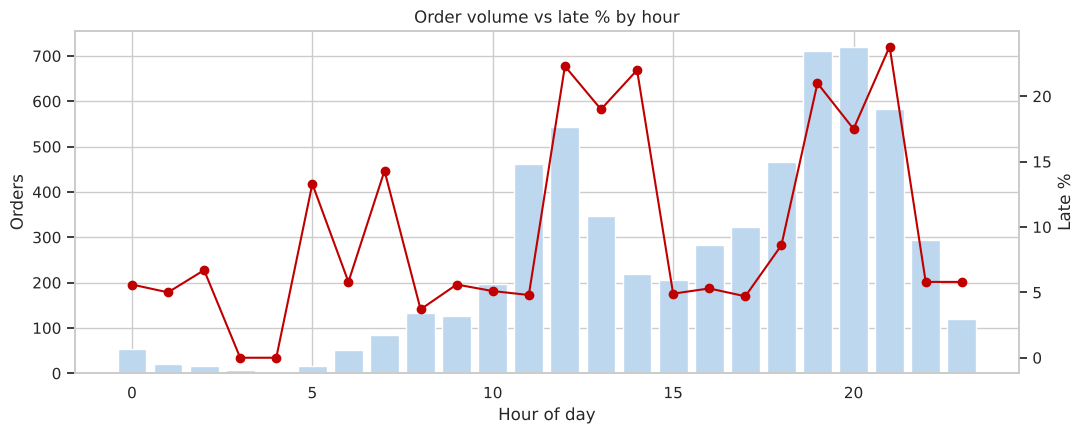

In [5]:
by_hour = df.groupby("hour").agg(orders=("order_id", "count"), late_pct=("is_late", lambda s: s.mean() * 100),
                                 avg_delay=("delay_min", "mean")).round(1)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(by_hour.index, by_hour.orders, color="#BDD7EE", label="Orders")
ax.set_ylabel("Orders"); ax.set_xlabel("Hour of day")
ax2 = ax.twinx(); ax2.plot(by_hour.index, by_hour.late_pct, color="#C00000", marker="o", label="Late %")
ax2.set_ylabel("Late %"); ax.set_title("Order volume vs late % by hour"); ax2.grid(False)
save("02_late_by_hour.png")
print(by_hour.sort_values("late_pct", ascending=False).head(5))

## 6. Weather, traffic and zone

         orders  avg_delay  late_pct
weather                             
Clear      3119       -3.6       9.0
Cloudy     1343       -3.1      10.1
Fog         336        0.1      17.9
Rain       1187        1.7      29.0
               orders  avg_delay  late_pct
traffic_level                             
High             1982        2.2      28.2
Low              1573       -6.9       2.7
Medium           2405       -2.8       8.8
Unknown            25       -2.8      20.0
                 orders  avg_delay  late_pct
zone                                        
Old Town            808       -1.2      16.8
Industrial Belt     514       -1.7      16.0
University Area     860       -2.6      14.2
Market Road         721       -1.4      13.9
Suburb North        617       -2.5      13.3
Tech Park           961       -2.9      12.7
Lakeview            707       -2.4      12.6
Riverside           797       -2.8      10.8

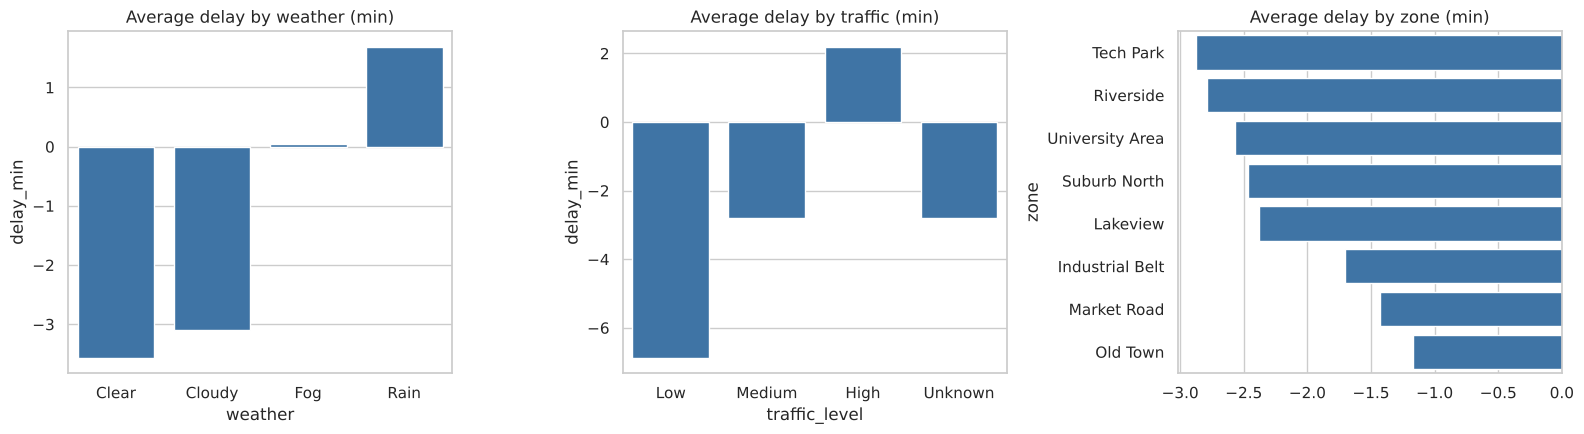

In [6]:
order_w = ["Clear", "Cloudy", "Fog", "Rain"]; order_t = ["Low", "Medium", "High", "Unknown"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(data=df, x="weather", y="delay_min", order=order_w, errorbar=None, ax=ax[0], color="#2E75B6")
ax[0].set_title("Average delay by weather (min)")
sns.barplot(data=df, x="traffic_level", y="delay_min", order=order_t, errorbar=None, ax=ax[1], color="#2E75B6")
ax[1].set_title("Average delay by traffic (min)")
z = df.groupby("zone").delay_min.mean().sort_values()
sns.barplot(x=z.values, y=z.index, ax=ax[2], color="#2E75B6"); ax[2].set_title("Average delay by zone (min)")
save("03_weather_traffic_zone.png")
print(df.groupby("weather").agg(orders=("order_id", "count"), avg_delay=("delay_min", "mean"), late_pct=("is_late", lambda s: s.mean()*100)).round(1))
print(df.groupby("traffic_level").agg(orders=("order_id", "count"), avg_delay=("delay_min", "mean"), late_pct=("is_late", lambda s: s.mean()*100)).round(1))
zone_tbl = df.groupby("zone").agg(orders=("order_id", "count"), avg_delay=("delay_min", "mean"), late_pct=("is_late", lambda s: s.mean()*100)).round(1).sort_values("late_pct", ascending=False)
print(zone_tbl)

## 7. Heatmap: weekday x hour band (average delay)

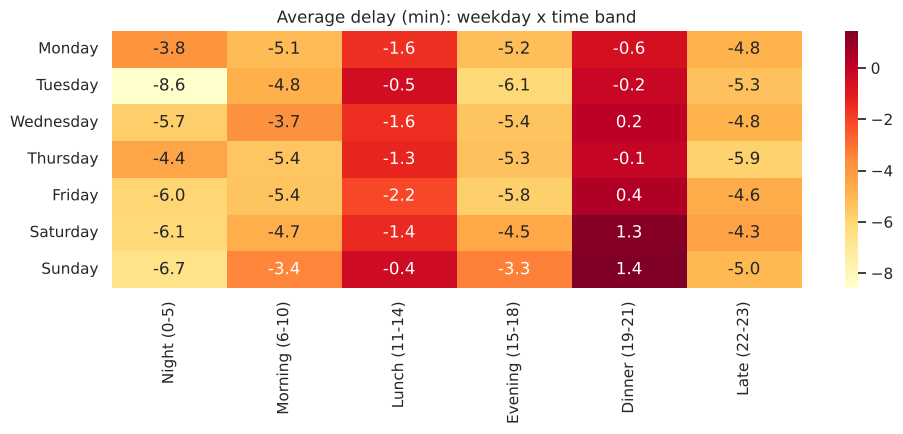

In [7]:
bins = [-1, 5, 10, 14, 18, 21, 23]; labels = ["Night (0-5)", "Morning (6-10)", "Lunch (11-14)", "Evening (15-18)", "Dinner (19-21)", "Late (22-23)"]
df["time_band"] = pd.cut(df.hour, bins=bins, labels=labels)
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = df.pivot_table(index="day_of_week", columns="time_band", values="delay_min", aggfunc="mean", observed=True).reindex(days)
plt.figure(figsize=(10, 4.5)); sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Average delay (min): weekday x time band"); plt.xlabel(""); plt.ylabel("")
save("04_heatmap_day_time.png")

## 8. Distance, prep time and courier experience

Each extra km adds about 0.41 minutes of delay (r = 0.13, R2 = 0.02)

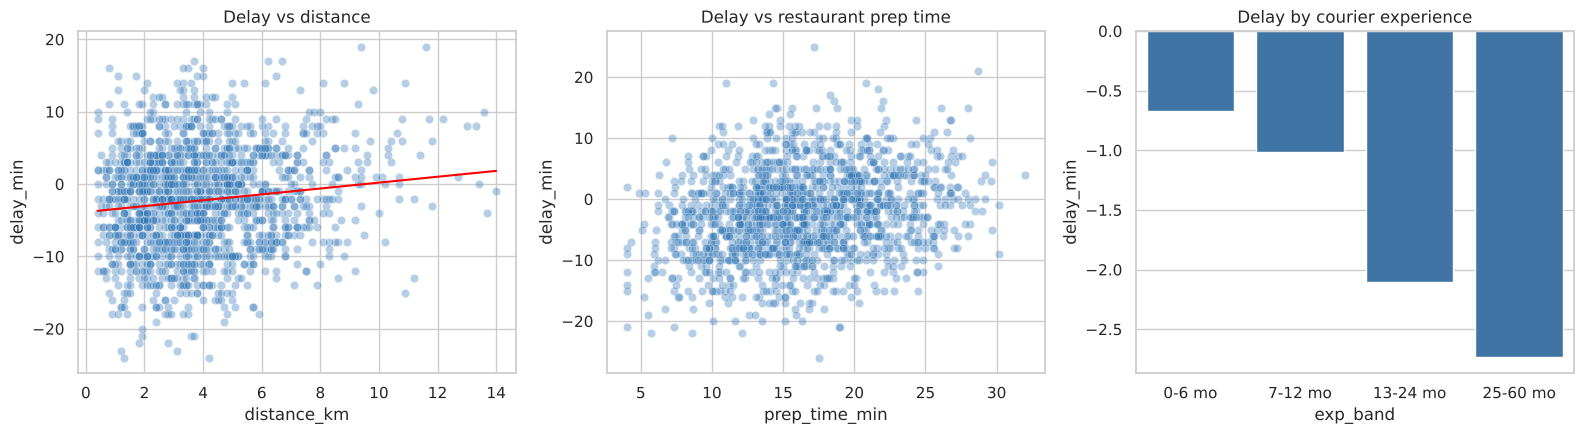

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=df.sample(1500, random_state=1), x="distance_km", y="delay_min", alpha=0.35, ax=ax[0], color="#2E75B6")
lr = stats.linregress(df.distance_km, df.delay_min)
xs = np.linspace(df.distance_km.min(), df.distance_km.max(), 50); ax[0].plot(xs, lr.intercept + lr.slope * xs, color="red")
ax[0].set_title("Delay vs distance")
sns.scatterplot(data=df.sample(1500, random_state=2), x="prep_time_min", y="delay_min", alpha=0.35, ax=ax[1], color="#2E75B6")
ax[1].set_title("Delay vs restaurant prep time")
df["exp_band"] = pd.cut(df.courier_experience_months, [0, 6, 12, 24, 60], labels=["0-6 mo", "7-12 mo", "13-24 mo", "25-60 mo"])
sns.barplot(data=df, x="exp_band", y="delay_min", errorbar=None, ax=ax[2], color="#2E75B6"); ax[2].set_title("Delay by courier experience")
save("05_distance_prep_experience.png")
print(f"Each extra km adds about {lr.slope:.2f} minutes of delay (r = {lr.rvalue:.2f}, R2 = {lr.rvalue**2:.2f})")

## 9. Correlation matrix

actual_time_min              0.68
prep_time_min                0.23
distance_km                  0.13
promised_time_min            0.11
items_count                  0.01
order_value                  0.00
courier_experience_months   -0.10
customer_rating             -0.37
Name: delay_min, dtype: float64

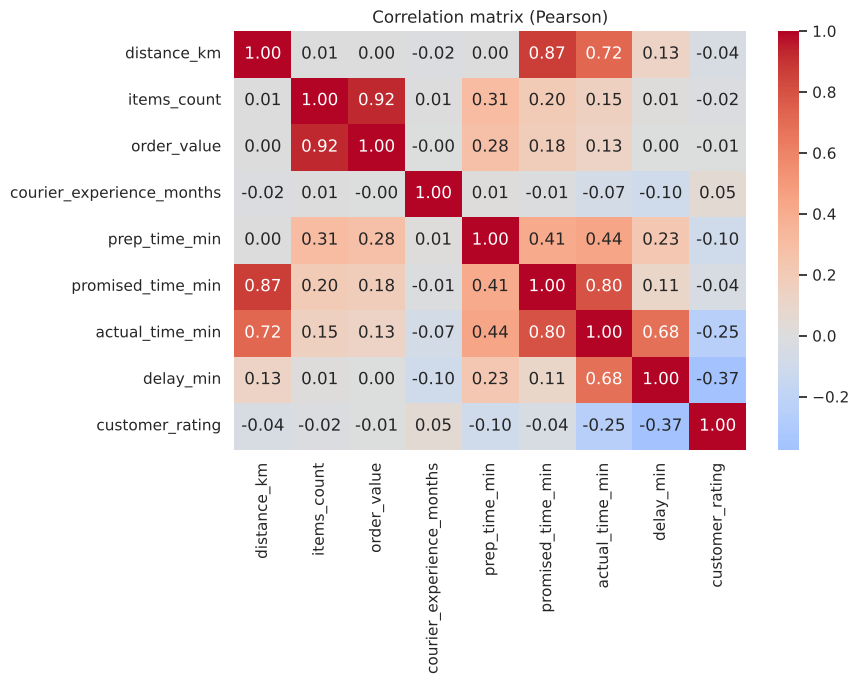

In [9]:
num_cols = ["distance_km", "items_count", "order_value", "courier_experience_months", "prep_time_min",
            "promised_time_min", "actual_time_min", "delay_min", "customer_rating"]
corr = df[num_cols].corr()
plt.figure(figsize=(9, 7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (Pearson)")
save("06_correlation.png")
print(corr["delay_min"].drop("delay_min").sort_values(ascending=False).round(2))

## 10. Statistical tests
Rule used: p-value below 0.05 = difference is unlikely to be pure chance.

In [10]:
res = {}
rain = df[df.weather == "Rain"].delay_min; clear = df[df.weather == "Clear"].delay_min
t, p = stats.ttest_ind(rain, clear, equal_var=False)
pooled = np.sqrt((rain.var() + clear.var()) / 2); d = (rain.mean() - clear.mean()) / pooled
res["rain_vs_clear"] = dict(rain_mean=rain.mean(), clear_mean=clear.mean(), t=t, p=p, cohens_d=d)
print(f"1) Welch t-test, Rain vs Clear delay: {rain.mean():.1f} vs {clear.mean():.1f} min, t={t:.1f}, p={p:.2g}, Cohen d={d:.2f}")

groups = [g.delay_min.values for n, g in df[df.traffic_level.isin(["Low", "Medium", "High"])].groupby("traffic_level")]
F, p = stats.f_oneway(*groups); res["traffic_anova"] = dict(F=F, p=p)
print(f"2) ANOVA delay across traffic levels: F={F:.1f}, p={p:.2g}")

ct = pd.crosstab(df.zone, df.is_late); chi, p, dof, _ = stats.chi2_contingency(ct); res["zone_chi2"] = dict(chi2=chi, p=p, dof=dof)
print(f"3) Chi-square late vs zone: chi2={chi:.1f}, dof={dof}, p={p:.2g}")

r, p = stats.pearsonr(df.distance_km, df.delay_min); res["distance_corr"] = dict(r=r, p=p)
print(f"4) Pearson distance vs delay: r={r:.2f}, p={p:.2g}")
r, p = stats.pearsonr(df.prep_time_min, df.delay_min); res["prep_corr"] = dict(r=r, p=p)
print(f"5) Pearson prep time vs delay: r={r:.2f}, p={p:.2g}")

rt = df.dropna(subset=["customer_rating"])
rho, p = stats.spearmanr(rt.delay_min, rt.customer_rating); res["rating_spearman"] = dict(rho=rho, p=p)
print(f"6) Spearman delay vs rating: rho={rho:.2f}, p={p:.2g}  (n={len(rt)})")

late_r = rt[rt.is_late == 1].customer_rating; ontime_r = rt[rt.is_late == 0].customer_rating
u, p = stats.mannwhitneyu(late_r, ontime_r); res["rating_late_vs_ontime"] = dict(late_mean=late_r.mean(), ontime_mean=ontime_r.mean(), p=p)
print(f"7) Mann-Whitney rating late vs on-time: {late_r.mean():.2f} vs {ontime_r.mean():.2f}, p={p:.2g}")

1) Welch t-test, Rain vs Clear delay: 1.7 vs -3.6 min, t=22.7, p=4.6e-102, Cohen d=0.77
2) ANOVA delay across traffic levels: F=967.6, p=0
3) Chi-square late vs zone: chi2=16.5, dof=7, p=0.021
4) Pearson distance vs delay: r=0.13, p=2.3e-25
5) Pearson prep time vs delay: r=0.23, p=4.1e-74
6) Spearman delay vs rating: rho=-0.36, p=2.4e-166  (n=5505)
7) Mann-Whitney rating late vs on-time: 4.08 vs 4.63, p=7.2e-121

## 11. Which factors matter most? (multiple linear regression)
Regression estimates the effect of each factor while the others are held fixed.

Effect on delay (minutes), other factors held fixed:
traffic_high                 7.32
rain                         5.34
fog                          3.74
peak_hour                    3.09
traffic_medium               2.99
weekend                      1.36
distance_km                  0.38
prep_time_min                0.31
courier_experience_months   -0.04

R-squared = 0.46  (share of delay variation explained by these factors)

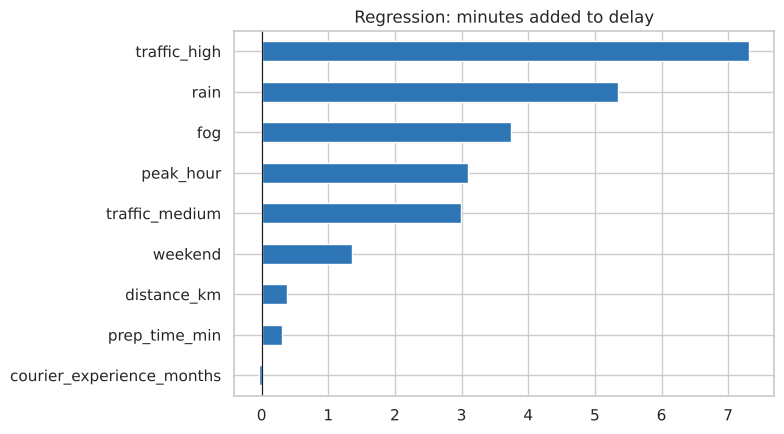

In [11]:
X = pd.DataFrame({
    "distance_km": df.distance_km, "prep_time_min": df.prep_time_min,
    "rain": (df.weather == "Rain").astype(int), "fog": (df.weather == "Fog").astype(int),
    "traffic_high": (df.traffic_level == "High").astype(int), "traffic_medium": (df.traffic_level == "Medium").astype(int),
    "peak_hour": df.is_peak_hour.astype(int), "weekend": df.is_weekend.astype(int),
    "courier_experience_months": df.courier_experience_months,
})
A = np.column_stack([np.ones(len(X)), X.values]); y = df.delay_min.values
beta, *_ = np.linalg.lstsq(A, y, rcond=None)
pred = A @ beta; r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
coef = pd.Series(beta[1:], index=X.columns).round(2)
print("Effect on delay (minutes), other factors held fixed:"); print(coef.sort_values(ascending=False).to_string())
print(f"\nR-squared = {r2:.2f}  (share of delay variation explained by these factors)")
plt.figure(figsize=(8, 4.5)); coef.sort_values().plot.barh(color="#2E75B6"); plt.title("Regression: minutes added to delay"); plt.axvline(0, color="k", lw=0.8)
save("07_regression_effects.png")
res["regression"] = dict(r2=r2, coef=coef.to_dict())

## 12. Customer rating and delay

                  mean  count
delay_band                   
On time or early  4.70   3614
0-5 late          4.41   1125
5-10 late         4.16    549
10-20 late        3.88    213
20+ late          3.75      4

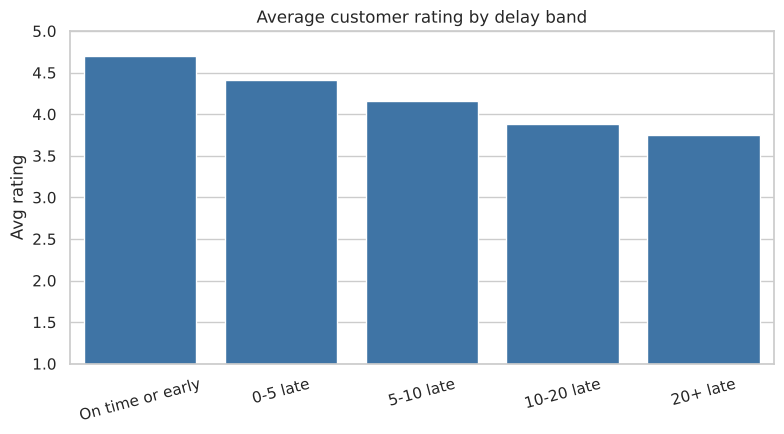

In [12]:
df["delay_band"] = pd.cut(df.delay_min, [-100, 0, 5, 10, 20, 100], labels=["On time or early", "0-5 late", "5-10 late", "10-20 late", "20+ late"])
rb = df.groupby("delay_band", observed=True).customer_rating.agg(["mean", "count"]).round(2)
print(rb)
plt.figure(figsize=(8, 4.5)); sns.barplot(x=rb.index, y=rb["mean"], color="#2E75B6"); plt.ylim(1, 5)
plt.title("Average customer rating by delay band"); plt.xlabel(""); plt.ylabel("Avg rating"); plt.xticks(rotation=15)
save("08_rating_by_delay.png")

## 13. Anomaly detection (IQR rule and z-score)

In [13]:
q1, q3 = df.delay_min.quantile([0.25, 0.75]); iqr = q3 - q1; hi = q3 + 1.5 * iqr; lo = q1 - 1.5 * iqr
out = df[(df.delay_min > hi) | (df.delay_min < lo)]
print(f"IQR limits: {lo:.1f} to {hi:.1f} min -> {len(out)} outlier orders ({len(out)/len(df)*100:.1f}%)")
df["z"] = stats.zscore(df.delay_min); extreme = df[df.z.abs() > 3]
print(f"Orders with |z| > 3: {len(extreme)}")
print("\nShare of extreme orders that happened in Rain or High traffic:",
      round(((extreme.weather == "Rain") | (extreme.traffic_level == "High")).mean() * 100, 1), "%")
print(extreme[["order_id", "zone", "weather", "traffic_level", "distance_km", "prep_time_min", "delay_min"]].sort_values("delay_min", ascending=False).head(8).to_string(index=False))

IQR limits: -22.0 to 18.0 min -> 26 outlier orders (0.4%)
Orders with |z| > 3: 11

Share of extreme orders that happened in Rain or High traffic: 45.5 %
order_id         zone weather traffic_level  distance_km  prep_time_min  delay_min
FD104814 Suburb North    Rain          High          6.8           17.2       25.0
FD104864  Market Road   Clear          High          6.0           25.8       22.0
FD103903 Suburb North    Rain          High          3.5           28.2       22.0
FD105556  Market Road   Clear          High          4.5           28.7       21.0
FD102482  Market Road  Cloudy          High          2.1           27.6       20.0
FD102167     Lakeview   Clear           Low          1.3           15.3      -24.0
FD101564     Lakeview   Clear           Low          4.4            5.8      -24.0
FD101142    Riverside   Clear           Low          3.6           18.0      -24.0

## 14. Business answers (auto-generated from the data)

In [14]:
worst_hour = by_hour[by_hour.orders >= 50].late_pct.idxmax()
worst_zone = zone_tbl.index[0]
w = df.groupby("weather").is_late.mean() * 100
tr = df.groupby("traffic_level").is_late.mean() * 100
peak_late = df[df.is_peak_hour].is_late.mean() * 100; off_late = df[~df.is_peak_hour].is_late.mean() * 100
answers = {
    "late_pct_overall": round(kpi["late_pct"], 1),
    "worst_hour": int(worst_hour), "worst_hour_late_pct": round(by_hour.loc[worst_hour, "late_pct"], 1),
    "worst_zone": worst_zone, "worst_zone_late_pct": float(zone_tbl.loc[worst_zone, "late_pct"]),
    "rain_late_pct": round(w["Rain"], 1), "clear_late_pct": round(w["Clear"], 1),
    "traffic_high_late_pct": round(tr["High"], 1), "traffic_low_late_pct": round(tr["Low"], 1),
    "peak_late_pct": round(peak_late, 1), "offpeak_late_pct": round(off_late, 1),
    "minutes_per_km": round(lr.slope, 2),
    "rating_late": round(late_r.mean(), 2), "rating_ontime": round(ontime_r.mean(), 2),
    "r2": round(r2, 2),
}
for k, v in answers.items(): print(f"{k:24s}: {v}")
with open(os.path.join(ROOT, "reports", "results.json"), "w") as f:
    json.dump({"kpi": kpi, "answers": answers, "tests": res}, f, indent=2, default=float)

late_pct_overall        : 13.7
worst_hour              : 21
worst_hour_late_pct     : 23.8
worst_zone              : Old Town
worst_zone_late_pct     : 16.8
rain_late_pct           : 29.0
clear_late_pct          : 9.0
traffic_high_late_pct   : 28.2
traffic_low_late_pct    : 2.7
peak_late_pct           : 20.8
offpeak_late_pct        : 5.9
minutes_per_km          : 0.41
rating_late             : 4.08
rating_ontime           : 4.63
r2                      : 0.46